# Лабораторна робота 2. Аналіз даних. Бібліотека Pandas

**Виконала:** Сєднєва Уляна, група 4-10  
**Варіант:** 19  
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/-.-Pandas.git

In [7]:
# Підключення бібліотек
import io
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

---
# Завдання 1. ВВП країн (Вікіпедія)

Зчитати датасет ВВП (млн дол. США) за країнами з Вікіпедії: https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)

In [8]:
# Зчитування таблиці з Вікіпедії
# (Вікіпедія відхиляє запити без заголовка User-Agent, тому завантажуємо сторінку через requests)
url = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'
html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0 (student lab work)'}, timeout=30).text
tables = pd.read_html(io.StringIO(html), match='IMF')
gdp_raw = max(tables, key=len)        # основна таблиця - найбільша серед знайдених

# Багаторівневі заголовки (джерело + Forecast/Estimate/Year) об'єднуємо в один рядок
if isinstance(gdp_raw.columns, pd.MultiIndex):
    gdp_raw.columns = [' '.join(dict.fromkeys(str(x) for x in col)).strip()
                       for col in gdp_raw.columns]
print('Знайдено таблиць:', len(tables))
print('Стовпці основної таблиці:', list(gdp_raw.columns))

Знайдено таблиць: 2
Стовпці основної таблиці: ['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


In [9]:
# 1. Вивести перших 5 рядків
gdp_raw.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


In [10]:
# 2. Визначити розмір датасета
print('Розмір датасету (рядки, стовпці):', gdp_raw.shape)

Розмір датасету (рядки, стовпці): (222, 4)


In [11]:
# 3. Визначити оптимальну кількість стовпців
# Для аналізу потрібні назва країни та три показники ВВП (МВФ, Світовий банк, ООН).
# Стовпці з роком оцінки (Year) лише вказують рік, тому їх не залишаємо.
country_col = gdp_raw.columns[0]

def is_year_col(c):
    # стовпець з роками: у назві є Year або майже всі значення - чотиризначні роки
    if 'year' in c.lower():
        return True
    s = gdp_raw[c].astype(str).str.replace(r'\[.*?\]', '', regex=True).str.strip()
    return s.str.fullmatch(r'(19|20)\d\d').mean() > 0.8

value_cols = []
for source in ['IMF', 'World Bank', 'United Nations']:
    cands = [c for c in gdp_raw.columns[1:] if source.lower() in c.lower() and not is_year_col(c)]
    if cands:
        value_cols.append(cands[0])
if len(value_cols) < 3:   # запасний варіант: перші три стовпці зі значеннями
    value_cols = [c for c in gdp_raw.columns[1:] if not is_year_col(c)][:3]

year_cols = [c for c in gdp_raw.columns[1:] if is_year_col(c)]
print('Стовпці зі значеннями ВВП:', value_cols)
for c in year_cols:
    print(f'Найчастіший рік у стовпці "{c}":', gdp_raw[c].mode().iloc[0])

gdp = gdp_raw[[country_col] + value_cols].copy()
print('\nОптимальна кількість стовпців:', gdp.shape[1])

Стовпці зі значеннями ВВП: ['IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']

Оптимальна кількість стовпців: 4


In [12]:
# 4. Змінити назви стовпців на більш зручні
gdp.columns = ['Country', 'MVF_2024', 'WorldBank_2023', 'OON_2022']
# прибираємо примітки виду [n 1] з назв країн
gdp['Country'] = gdp['Country'].astype(str).str.replace(r'\[.*?\]', '', regex=True).str.strip()
# рядок "World" - сума по всіх країнах, а не країна; для аналізу країн його видаляємо
world_row = gdp[gdp['Country'] == 'World']
gdp = gdp[gdp['Country'] != 'World'].reset_index(drop=True)
print('Видалено агрегований рядок World:', len(world_row))
gdp.head()

Видалено агрегований рядок World: 1


,Country,MVF_2024,WorldBank_2023,OON_2022
0,United States,32642373,30769700,29298000
1,China,21546403,19498039,18743802
2,Germany,5471299,5050923,4659929
3,Japan,4341986,4435163,4026211
4,United Kingdom,4268446,4002588,3685881


In [13]:
# 5. Визначити тип даних
gdp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Country         221 non-null    object
 1   MVF_2024        221 non-null    object
 2   WorldBank_2023  221 non-null    object
 3   OON_2022        221 non-null    object
dtypes: object(4)
memory usage: 7.0+ KB


In [14]:
# 6. Замінити "—" на NaN, перевірити пропуски та замінити їх середнім значенням
num_cols = ['MVF_2024', 'WorldBank_2023', 'OON_2022']
for c in num_cols:
    gdp[c] = (gdp[c].astype(str)
              .str.replace(r'\[.*?\]', '', regex=True)   # примітки
              .str.replace(',', '', regex=False)           # роздільники тисяч
              .str.strip()
              .replace({'—': np.nan, '–': np.nan, '-': np.nan, 'nan': np.nan}))
    gdp[c] = pd.to_numeric(gdp[c], errors='coerce')

print('Типи після перетворення:\n', gdp.dtypes, '\n')
print('Кількість пропущених значень:\n', gdp[num_cols].isna().sum())

imputed_mask = gdp[num_cols].isna().any(axis=1)   # запам'ятовуємо країни з пропусками
gdp[num_cols] = gdp[num_cols].fillna(gdp[num_cols].mean())
print('\nКраїн, у яких були пропуски (замінено середнім):', int(imputed_mask.sum()))

Типи після перетворення:
 Country            object
MVF_2024          float64
WorldBank_2023    float64
OON_2022          float64
dtype: object 

Кількість пропущених значень:
 MVF_2024          30
WorldBank_2023    35
OON_2022           9
dtype: int64

Країн, у яких були пропуски (замінено середнім): 38


In [15]:
# 7. Ще раз перевірити наявність пропущених значень
print(gdp.isna().sum())

Country           0
MVF_2024          0
WorldBank_2023    0
OON_2022          0
dtype: int64


In [16]:
# 8. Перевірити наявність дублікатів та видалити їх
print('Повних дублікатів рядків:', gdp.duplicated().sum())
print('Дублікатів назв країн:', gdp['Country'].duplicated().sum())
gdp = gdp.drop_duplicates().reset_index(drop=True)
print('Розмір після видалення дублікатів:', gdp.shape)

Повних дублікатів рядків: 0
Дублікатів назв країн: 0
Розмір після видалення дублікатів: (221, 4)


In [17]:
# 9. Описова статистика
gdp.describe()

,MVF_2024,WorldBank_2023,OON_2022
count,221.00,221.00,221.00
mean,"669,028.94","626,049.69","522,491.21"
std,"2,705,629.40","2,520,399.39","2,410,079.31"
min,65.00,57.00,56.00
25%,"18,959.00","19,928.00","8,840.00"
50%,"102,042.00","99,774.00","42,765.00"
75%,"669,028.94","626,049.69","298,697.00"
max,"32,642,373.00","30,769,700.00","29,298,000.00"


In [18]:
# 10. Відхилення між MVF_2024 та WorldBank_2023 для кожної країни
gdp['Diff_MVF_WB'] = gdp['MVF_2024'] - gdp['WorldBank_2023']
gdp['AbsDiff'] = gdp['Diff_MVF_WB'].abs()
gdp['Diff_%'] = gdp['Diff_MVF_WB'] / gdp['WorldBank_2023'] * 100

real = gdp[~imputed_mask.values]                 # лише країни без заповнених пропусків
top_abs = real.nlargest(5, 'AbsDiff')[['Country', 'MVF_2024', 'WorldBank_2023', 'Diff_MVF_WB', 'Diff_%']]
top_rel = real.reindex(real['Diff_%'].abs().nlargest(5).index)[['Country', 'MVF_2024', 'WorldBank_2023', 'Diff_MVF_WB', 'Diff_%']]
print('Найбільші відхилення в абсолютних значеннях (млн дол.):')
display(top_abs)
print('Найбільші відхилення у відсотках:')
display(top_rel)
print(f"Відповідь: в абсолютних значеннях показники найбільше відрізняються у країнах "
      f"{', '.join(top_abs['Country'].head(3))}; у відносних - у {', '.join(top_rel['Country'].head(3))}.")

Найбільші відхилення в абсолютних значеннях (млн дол.):


,Country,MVF_2024,WorldBank_2023,Diff_MVF_WB,Diff_%
1,China,"21,546,403.00","19,498,039.00","2,048,364.00",10.51
0,United States,"32,642,373.00","30,769,700.00","1,872,673.00",6.09
2,Germany,"5,471,299.00","5,050,923.00","420,376.00",8.32
9,Brazil,"2,654,761.00","2,279,920.00","374,841.00",16.44
11,South Korea,"2,245,847.00","1,872,375.00","373,472.00",19.95


Найбільші відхилення у відсотках:


,Country,MVF_2024,WorldBank_2023,Diff_MVF_WB,Diff_%
163,Burundi,"8,137.00","3,365.00","4,772.00",141.81
88,Turkmenistan,"83,065.00","49,829.00","33,236.00",66.70
109,Zambia,"41,243.00","28,880.00","12,363.00",42.81
72,DR Congo,"122,281.00","91,031.00","31,250.00",34.33
47,Nigeria,"386,671.00","290,794.00","95,877.00",32.97


Відповідь: в абсолютних значеннях показники найбільше відрізняються у країнах China, United States, Germany; у відносних - у Burundi, Turkmenistan, Zambia.


In [19]:
# 11. Кореляція між MVF_2024, WorldBank_2023 та OON_2022
corr = gdp[num_cols].corr()
display(corr)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print(pairs)
print(f'Відповідь: найвища кореляція між {pairs.index[0][0]} та {pairs.index[0][1]} (r = {pairs.iloc[0]:.4f}).')

,MVF_2024,WorldBank_2023,OON_2022
MVF_2024,1.00,1.00,1.00
WorldBank_2023,1.00,1.00,1.00
OON_2022,1.00,1.00,1.00


MVF_2024        WorldBank_2023   1.00
                OON_2022         1.00
WorldBank_2023  OON_2022         1.00
dtype: float64
Відповідь: найвища кореляція між MVF_2024 та WorldBank_2023 (r = 0.9985).


In [20]:
# 12. Середнє значення для кожного стовпця та його зміна між роками
means = gdp[num_cols].mean()
print(means)
print(f"\nЗміна OON_2022 -> WorldBank_2023: {means['WorldBank_2023'] - means['OON_2022']:+,.0f} млн дол. "
      f"({(means['WorldBank_2023'] / means['OON_2022'] - 1) * 100:+.2f} %)")
print(f"Зміна WorldBank_2023 -> MVF_2024: {means['MVF_2024'] - means['WorldBank_2023']:+,.0f} млн дол. "
      f"({(means['MVF_2024'] / means['WorldBank_2023'] - 1) * 100:+.2f} %)")

MVF_2024         669,028.94
WorldBank_2023   626,049.69
OON_2022         522,491.21
dtype: float64

Зміна OON_2022 -> WorldBank_2023: +103,558 млн дол. (+19.82 %)
Зміна WorldBank_2023 -> MVF_2024: +42,979 млн дол. (+6.87 %)


In [21]:
# 13. Стандартне відхилення показників для кожної країни
gdp['Std'] = gdp[num_cols].std(axis=1)
gdp['CV_%'] = gdp['Std'] / gdp[num_cols].mean(axis=1) * 100   # відносна варіативність
real = gdp[~imputed_mask.values]
print('Найбільше стандартне відхилення (абсолютна варіативність):')
display(real.nlargest(5, 'Std')[['Country'] + num_cols + ['Std']])
print('Найбільший коефіцієнт варіації (відносна варіативність):')
display(real.nlargest(5, 'CV_%')[['Country'] + num_cols + ['CV_%']])
print(f"Відповідь: найвища абсолютна варіативність - {real.loc[real['Std'].idxmax(), 'Country']}, "
      f"найвища відносна - {real.loc[real['CV_%'].idxmax(), 'Country']}.")

Найбільше стандартне відхилення (абсолютна варіативність):


,Country,MVF_2024,WorldBank_2023,OON_2022,Std
0,United States,"32,642,373.00","30,769,700.00","29,298,000.00","1,676,187.93"
1,China,"21,546,403.00","19,498,039.00","18,743,802.00","1,450,243.71"
2,Germany,"5,471,299.00","5,050,923.00","4,659,929.00","405,773.66"
7,Russia,"2,861,156.00","2,561,310.00","2,173,386.00","344,823.68"
4,United Kingdom,"4,268,446.00","4,002,588.00","3,685,881.00","291,652.13"


Найбільший коефіцієнт варіації (відносна варіативність):


,Country,MVF_2024,WorldBank_2023,OON_2022,CV_%
163,Burundi,"8,137.00","3,365.00","4,431.00",47.16
105,Sudan,"44,688.00","60,163.00","25,574.00",39.85
89,Bolivia,"80,743.00","64,769.00","46,627.00",26.65
109,Zambia,"41,243.00","28,880.00","25,303.00",26.29
72,DR Congo,"122,281.00","91,031.00","75,322.00",24.85


Відповідь: найвища абсолютна варіативність - United States, найвища відносна - Burundi.


In [22]:
# 14. Країни з найвищим та найнижчим показниками в кожному році
for c in num_cols:
    hi, lo = gdp.loc[gdp[c].idxmax()], gdp.loc[gdp[c].idxmin()]
    print(f"{c}: найвищий - {hi['Country']} ({hi[c]:,.0f}), найнижчий - {lo['Country']} ({lo[c]:,.0f})")

MVF_2024: найвищий - United States (32,642,373), найнижчий - Tuvalu (65)
WorldBank_2023: найвищий - United States (30,769,700), найнижчий - Tuvalu (57)
OON_2022: найвищий - United States (29,298,000), найнижчий - Tuvalu (56)


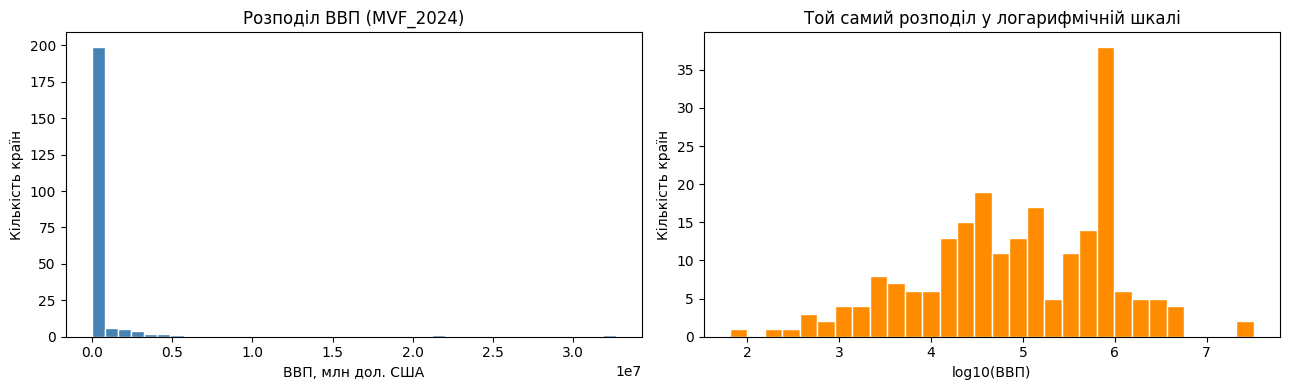

Медіана: 102,042, середнє: 669,029
Країн, що виділяються (вище Q3 + 1.5·IQR): 16; найбільші: United States, China, Germany, Japan, United Kingdom


In [23]:
# 15. Гістограма розподілу MVF_2024
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(gdp['MVF_2024'], bins=40, color='steelblue', edgecolor='white')
axes[0].set(title='Розподіл ВВП (MVF_2024)', xlabel='ВВП, млн дол. США', ylabel='Кількість країн')
axes[1].hist(np.log10(gdp['MVF_2024']), bins=30, color='darkorange', edgecolor='white')
axes[1].set(title='Той самий розподіл у логарифмічній шкалі', xlabel='log10(ВВП)', ylabel='Кількість країн')
plt.tight_layout()
plt.show()

q1, q3 = gdp['MVF_2024'].quantile([0.25, 0.75])
outl = gdp[gdp['MVF_2024'] > q3 + 1.5 * (q3 - q1)].sort_values('MVF_2024', ascending=False)
print(f"Медіана: {gdp['MVF_2024'].median():,.0f}, середнє: {gdp['MVF_2024'].mean():,.0f}")
print(f"Країн, що виділяються (вище Q3 + 1.5·IQR): {len(outl)}; найбільші: {', '.join(outl['Country'].head(5))}")

In [24]:
# 16. Частка кожної країни в загальному значенні для кожного року
shares = gdp[['Country']].copy()
for c in num_cols:
    shares[c + '_share_%'] = gdp[c] / gdp[c].sum() * 100
shares['Зміна частки_2022→2024'] = shares['MVF_2024_share_%'] - shares['OON_2022_share_%']
top10 = shares.sort_values('MVF_2024_share_%', ascending=False).head(10)
display(top10)
print(f"Частка 10 найбільших економік у 2024: {top10['MVF_2024_share_%'].sum():.1f} %")
gain = shares.nlargest(3, 'Зміна частки_2022→2024')['Country'].tolist()
loss = shares.nsmallest(3, 'Зміна частки_2022→2024')['Country'].tolist()
print('Найбільше зросла частка:', ', '.join(gain))
print('Найбільше зменшилась частка:', ', '.join(loss))

,Country,MVF_2024_share_%,WorldBank_2023_share_%,OON_2022_share_%,Зміна частки_2022→2024
0,United States,22.08,22.24,25.37,-3.30
1,China,14.57,14.09,16.23,-1.66
2,Germany,3.70,3.65,4.04,-0.34
3,Japan,2.94,3.21,3.49,-0.55
4,United Kingdom,2.89,2.89,3.19,-0.31
5,India,2.75,2.86,3.42,-0.68
6,France,2.40,2.43,2.74,-0.33
7,Russia,1.94,1.85,1.88,0.05
8,Italy,1.83,1.84,2.06,-0.23
9,Brazil,1.80,1.65,1.89,-0.10


Частка 10 найбільших економік у 2024: 56.9 %
Найбільше зросла частка: Montserrat, Cook Islands, Anguilla
Найбільше зменшилась частка: United States, China, India


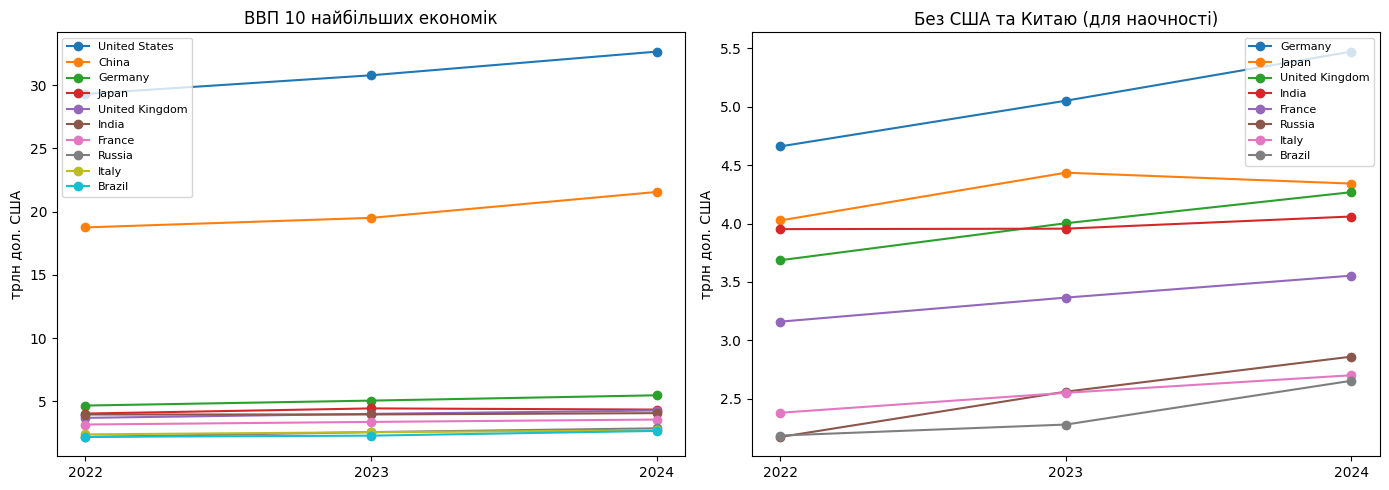

Стабільне зростання (2022 < 2023 < 2024): 157 країн з 183
  серед 10 найбільших: United States, China, Germany, United Kingdom, India, France, Russia, Italy, Brazil
Стабільний спад (2022 > 2023 > 2024): 4 країн
  приклади: Kuwait, Qatar, Iraq, Iran
  найбільші за розміром економіки зі спадом: Iran, Iraq, Qatar, Kuwait


In [25]:
# 17. Зміни показників для країн за три роки
years = ['OON_2022', 'WorldBank_2023', 'MVF_2024']          # у хронологічному порядку
top = gdp.nlargest(10, 'MVF_2024').set_index('Country')[years]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for country, row in top.iterrows():
    axes[0].plot(['2022', '2023', '2024'], row.values / 1e6, marker='o', label=country)
axes[0].set(title='ВВП 10 найбільших економік', ylabel='трлн дол. США')
axes[0].legend(fontsize=8)
for country, row in top.iloc[2:].iterrows():
    axes[1].plot(['2022', '2023', '2024'], row.values / 1e6, marker='o', label=country)
axes[1].set(title='Без США та Китаю (для наочності)', ylabel='трлн дол. США')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

real = gdp[~imputed_mask.values]
growth = real[(real['WorldBank_2023'] > real['OON_2022']) & (real['MVF_2024'] > real['WorldBank_2023'])]
decline = real[(real['WorldBank_2023'] < real['OON_2022']) & (real['MVF_2024'] < real['WorldBank_2023'])]
print(f'Стабільне зростання (2022 < 2023 < 2024): {len(growth)} країн з {len(real)}')
print('  серед 10 найбільших:', ', '.join(c for c in top.index if c in set(growth['Country'])))
print(f'Стабільний спад (2022 > 2023 > 2024): {len(decline)} країн')
print('  приклади:', ', '.join(decline.nsmallest(5, 'MVF_2024')['Country'] if len(decline) else []))
print('  найбільші за розміром економіки зі спадом:', ', '.join(decline.nlargest(5, 'MVF_2024')['Country']))

### Висновок до завдання 1


Таблицю ВВП країн було зчитано з Вікіпедії та підготовлено до аналізу. З усіх стовпців залишено назву країни та три показники: МВФ, Світовий банк та ООН. Стовпці названо `MVF_2024`, `WorldBank_2023` і `OON_2022`, як вимагає методичка, хоча у Вікіпедії зараз розміщено новіші дані: прогноз МВФ на 2026 рік, оцінку Світового банку за 2025 рік та оцінку ООН за 2024 рік. Тому далі «2022 → 2024» означає порядок від найстарішої оцінки до найновішої. Агрегований рядок World видалено, оскільки він є сумою по всіх країнах.

Після перетворення в числовий формат виявлено пропуски: 30 у даних МВФ, 35 у даних Світового банку та 9 у даних ООН, загалом у 38 країнах. Їх замінено середнім значенням стовпця. Дублікатів не знайдено, тож для аналізу залишилося 221 країна.

Розподіл ВВП дуже нерівномірний. Медіана за даними МВФ становить близько 102 млрд дол., а середнє — близько 669 млрд дол., тобто в 6,5 раза більше. Отже, середнє значення сильно завищують кілька найбільших економік. На гістограмі майже всі країни потрапляють у перший інтервал, і лише в логарифмічній шкалі видно форму розподілу. За правилом Q3 + 1,5·IQR виділяються 16 країн, найбільші з них — США, Китай, Німеччина, Японія та Велика Британія. Найбільший ВВП за всіма трьома джерелами має США (32,6 трлн дол. за МВФ), найменший — Тувалу (65 млн дол.). Частка 10 найбільших економік становить 56,9 % світового ВВП, а частка однієї лише США — 22,1 %.

Показники трьох організацій майже однакові: коефіцієнти кореляції між ними близькі до 1, найвищий між МВФ і Світовим банком (r = 0,9985). В абсолютних значеннях оцінки найбільше розходяться для Китаю (2,05 трлн дол.), США та Німеччини, тобто для найбільших економік. У відсотках розходження найбільші для Бурунді (141,8 %), Туркменістану (66,7 %) та Замбії (42,8 %), де економічна статистика менш надійна. Аналогічно за стандартним відхиленням найбільш варіативний показник у США, а за коефіцієнтом варіації — у Бурунді (47,2 %).

Від найстарішої оцінки до найновішої середній ВВП зріс з 522 до 626 млрд дол. (+19,8 %), а потім до 669 млрд дол. (+6,9 %). Стабільне зростання за всіма трьома оцінками показали 157 країн зі 183, у яких не було пропусків, зокрема всі 10 найбільших економік. Стабільний спад спостерігався лише в 4 країнах: Ірані, Іраку, Катарі та Кувейті. Водночас частки США, Китаю та Індії у світовому ВВП трохи зменшилися: інші країни зростали швидше.

---
# Завдання 2. Титанік

In [26]:
# Завантаження датасету Титанік
# (якщо файл titanic.csv уже завантажено в Colab - читаємо його, інакше - з відкритого джерела)
import os
if os.path.exists('titanic.csv'):
    titanic = pd.read_csv('titanic.csv')
else:
    titanic = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

In [27]:
# 1. Вивести перших 5 рядків
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [28]:
# 2. Визначити розмір датасета
print('Розмір датасету (рядки, стовпці):', titanic.shape)

Розмір датасету (рядки, стовпці): (891, 12)


In [29]:
# 3. Визначити тип даних
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [30]:
# 4. Наявність пропущених значень і заміна
print('Пропущені значення до заміни:\n', titanic.isna().sum()[titanic.isna().sum() > 0], '\n')

# Числові пропуски (Age) замінюємо середнім значенням.
# Для текстових стовпців середнє не існує: Embarked заповнюємо найчастішим значенням (модою),
# а Cabin (77 % пропусків) не заповнюємо - він буде видалений у пункті 8.
print(f"Середній вік, яким заповнюємо пропуски: {titanic['Age'].mean():.2f}")
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].mean())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])

Пропущені значення до заміни:
 Age         177
Cabin       687
Embarked      2
dtype: int64 

Середній вік, яким заповнюємо пропуски: 29.70


In [31]:
# 5. Ще раз перевірити наявність пропущених значень
print(titanic.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [32]:
# 6. Перевірити наявність дублікатів та видалити їх
print('Кількість дублікатів:', titanic.duplicated().sum())
titanic = titanic.drop_duplicates()
print('Розмір після перевірки:', titanic.shape)

Кількість дублікатів: 0
Розмір після перевірки: (891, 12)


In [33]:
# 7. Описова статистика
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,13.00,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,22.00,0.00,0.00,7.91
50%,446.00,0.00,3.00,29.70,0.00,0.00,14.45
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [34]:
# 8. Видалити стовпчик Cabin
titanic = titanic.drop(columns='Cabin')
print('Стовпці:', list(titanic.columns))

Стовпці: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']


In [35]:
# 9. Сформувати датасет з обраними стовпцями
df = titanic[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']].copy()
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.00,7.25
1,1,1,female,38.00,71.28
2,1,3,female,26.00,7.92
3,1,1,female,35.00,53.10
4,0,3,male,35.00,8.05


In [36]:
# 10. Замінити бінарні ознаки (Sex) на 0 і 1
print('Унікальні значення Sex:', df['Sex'].unique())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
print('Після заміни:', df['Sex'].unique(), '(0 - чоловік, 1 - жінка)')

Унікальні значення Sex: ['male' 'female']
Після заміни: [0 1] (0 - чоловік, 1 - жінка)


In [37]:
# 11. Ще раз перевірити кількість пропущених даних
print(df.isna().sum())

Survived    0
Pclass      0
Sex         0
Age         0
Fare        0
dtype: int64


In [38]:
# 12. Вивести 5 перших рядків
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.00,7.25
1,1,1,1,38.00,71.28
2,1,3,1,26.00,7.92
3,1,1,1,35.00,53.10
4,0,3,0,35.00,8.05


In [39]:
# 13. Вивести 5 останніх рядків
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.00,13.00
887,1,1,1,19.00,30.00
888,0,3,1,29.70,23.45
889,1,1,0,26.00,30.00
890,0,3,0,32.00,7.75


In [40]:
# 14. Відсоток виживання для кожної статі
surv_sex = df.groupby('Sex')['Survived'].mean().mul(100).rename({0: 'Чоловіки', 1: 'Жінки'})
print(surv_sex.round(2))
print(f"Відповідь: так, жінки виживали в {surv_sex['Жінки'] / surv_sex['Чоловіки']:.1f} раза частіше за чоловіків.")

Sex
Чоловіки   18.89
Жінки      74.20
Name: Survived, dtype: float64
Відповідь: так, жінки виживали в 3.9 раза частіше за чоловіків.


In [41]:
# 15. Відсоток виживання для кожного класу
surv_class = df.groupby('Pclass')['Survived'].mean().mul(100)
print(surv_class.round(2))
print(f'Відповідь: найвищий рівень виживання мав {surv_class.idxmax()}-й клас ({surv_class.max():.1f} %).')

Pclass
1   62.96
2   47.28
3   24.24
Name: Survived, dtype: float64
Відповідь: найвищий рівень виживання мав 1-й клас (63.0 %).


In [42]:
# 16. Середній вік тих, хто вижив, і тих, хто не вижив
age_surv = df.groupby('Survived')['Age'].mean().rename({0: 'Не вижили', 1: 'Вижили'})
print(age_surv.round(2))
print('Кореляція віку з виживанням:', round(df['Age'].corr(df['Survived']), 3))

Survived
Не вижили   30.42
Вижили      28.55
Name: Age, dtype: float64
Кореляція віку з виживанням: -0.07


In [43]:
# 17. Рівень виживання за групами тарифів (квартилі Fare)
df['FareGroup'] = pd.qcut(df['Fare'], 4, labels=['Низький', 'Нижче середнього', 'Вище середнього', 'Високий'])
fare_surv = df.groupby('FareGroup', observed=True).agg(
    Межі_тарифу=('Fare', lambda s: f'{s.min():.1f}–{s.max():.1f}'),
    Пасажирів=('Survived', 'size'),
    Виживання_pct=('Survived', lambda s: s.mean() * 100))
fare_surv

,Межі_тарифу,Пасажирів,Виживання_pct
FareGroup,,,
Низький,0.0–7.9,223,19.73
Нижче середнього,7.9–14.5,224,30.36
Вище середнього,14.5–31.0,222,45.50
Високий,31.3–512.3,222,58.11


In [44]:
# 18. Середній тариф для кожного класу
fare_class = df.groupby('Pclass')['Fare'].mean()
print(fare_class.round(2))
print(f'Тариф 1-го класу більший за тариф 3-го у {fare_class[1] / fare_class[3]:.1f} раза.')

Pclass
1   84.15
2   20.66
3   13.68
Name: Fare, dtype: float64
Тариф 1-го класу більший за тариф 3-го у 6.2 раза.


In [45]:
# 19. Середній вік пасажирів для кожного класу
age_class = df.groupby('Pclass')['Age'].mean()
print(age_class.round(2))

Pclass
1   37.05
2   29.87
3   26.40
Name: Age, dtype: float64


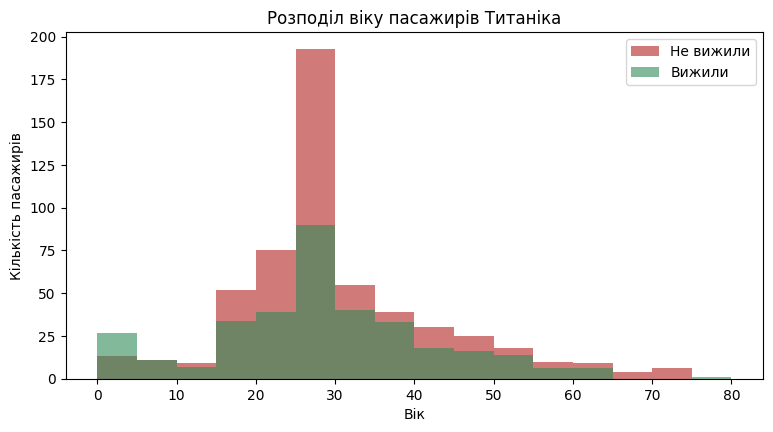

Виживання за віковими групами, %:
Age
0–12    58.00
13–18   42.90
19–30   33.10
31–50   42.30
51–80   34.40
Name: Survived, dtype: float64


In [46]:
# 20. Гістограма розподілу віку для тих, хто вижив і не вижив
plt.figure(figsize=(9, 4.5))
bins = np.arange(0, 85, 5)
plt.hist(df[df['Survived'] == 0]['Age'], bins=bins, alpha=0.6, label='Не вижили', color='firebrick')
plt.hist(df[df['Survived'] == 1]['Age'], bins=bins, alpha=0.6, label='Вижили', color='seagreen')
plt.xlabel('Вік'); plt.ylabel('Кількість пасажирів')
plt.title('Розподіл віку пасажирів Титаніка')
plt.legend()
plt.show()

age_groups = pd.cut(df['Age'], [0, 12, 18, 30, 50, 80], labels=['0–12', '13–18', '19–30', '31–50', '51–80'])
print('Виживання за віковими групами, %:')
print(df.groupby(age_groups, observed=True)['Survived'].mean().mul(100).round(1))

In [47]:
# 21. Відсоток виживання для кожної комбінації статі та класу
combo = (df.assign(Стать=df['Sex'].map({0: 'Чоловіки', 1: 'Жінки'}))
           .pivot_table(index='Стать', columns='Pclass', values='Survived', aggfunc='mean') * 100)
display(combo.round(1))
best = combo.stack().idxmax(); worst = combo.stack().idxmin()
print(f'Найвищий рівень виживання: {best[0].lower()} у {best[1]}-му класі ({combo.stack().max():.1f} %)')
print(f'Найнижчий: {worst[0].lower()} у {worst[1]}-му класі ({combo.stack().min():.1f} %)')

Pclass,1,2,3
Стать,,,
Жінки,96.80,92.10,50.00
Чоловіки,36.90,15.70,13.50


Найвищий рівень виживання: жінки у 1-му класі (96.8 %)
Найнижчий: чоловіки у 3-му класі (13.5 %)


In [48]:
# 22. Кореляція між числовими змінними
corr_t = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']].corr()
display(corr_t.round(3))
print('Кореляція з Survived (за спаданням модуля):')
print(corr_t['Survived'].drop('Survived').sort_values(key=abs, ascending=False).round(3))

,Survived,Pclass,Sex,Age,Fare
Survived,1.00,-0.34,0.54,-0.07,0.26
Pclass,-0.34,1.00,-0.13,-0.33,-0.55
Sex,0.54,-0.13,1.00,-0.08,0.18
Age,-0.07,-0.33,-0.08,1.00,0.09
Fare,0.26,-0.55,0.18,0.09,1.00


Кореляція з Survived (за спаданням модуля):
Sex       0.54
Pclass   -0.34
Fare      0.26
Age      -0.07
Name: Survived, dtype: float64


### Висновок до завдання 2

Датасет Titanic містить 891 пасажира та 12 ознак. Пропуски виявлено у трьох стовпцях: вік (177), каюта (687, тобто 77 %) та порт посадки (2). Пропущений вік замінено середнім значенням 29,70 року, порт посадки — найчастішим значенням. Стовпець Cabin видалено, оскільки більшість його значень відсутні. Дублікатів у даних немає. Для аналізу сформовано датасет зі стовпців Survived, Pclass, Sex, Age та Fare, а стать закодовано числами: 0 — чоловік, 1 — жінка.

Загалом вижило лише 38 % пасажирів. Найсильніше на виживання вплинула стать: жінки вижили у 74,2 % випадків, чоловіки — лише у 18,9 %, тобто в 3,9 раза рідше. Це підтверджує правило «спочатку жінки та діти». Другим за важливістю чинником був клас каюти: у 1-му класі вижили 63,0 % пасажирів, у 2-му — 47,3 %, у 3-му — лише 24,2 %. Зведена таблиця показує, що ці два чинники посилюють один одного: найвищий рівень виживання мали жінки 1-го класу (96,8 %), найнижчий — чоловіки 3-го класу (13,5 %).

Вартість квитка пов’язана з класом: середній тариф 1-го класу (84,15 дол.) у 6,2 раза більший, ніж 3-го (13,68 дол.). Тому з ростом тарифу зростає і виживання: від 19,7 % у групі з найдешевшими квитками до 58,1 % у групі з найдорожчими. Пасажири 1-го класу були в середньому старшими (37,1 року), ніж пасажири 3-го класу (26,4 року).

Вік вплинув на виживання слабко: середній вік тих, хто вижив, становить 28,6 року, а тих, хто загинув, — 30,4 року. Найвищий рівень виживання мали діти до 12 років (58 %), найнижчий — пасажири 19–30 років (33,1 %). Пік на гістограмі в інтервалі 25–30 років штучний: його утворили 177 пропусків, замінених середнім віком.

Кореляційний аналіз підтверджує ці висновки. Найсильніше з виживанням пов’язані стать (r = 0,54), клас (r = −0,34; що вищий номер класу, то нижче виживання) та тариф (r = 0,26). Зв’язок із віком майже відсутній (r = −0,07). Отже, шанси врятуватися визначали насамперед стать і соціальний статус пасажира.